# META: stationarity, volatility, and trend signals

Matias Freer · AN 306 academic portfolio

**My contribution:** Stationarity, ACF/PACF and initial ARIMA setup, volatility/outliers, moving averages, and visualization. This fixed-date rerun does not implement the broader team forecast.

See README.md for team credits, findings, limitations, and setup. Original saved work is in original_analysis.ipynb. Data files are excluded from GitHub; place the input under data/ or set AN306_INPUT.

## Analysis implementation

The implementation matches analysis.py. Assertions check key assumptions before creating tables and figures.

In [1]:
"""Reproducible portfolio edition of the stationarity and trend analysis.

Requires a CSV snapshot with Date, Close, and Volume. Optional Yahoo download
uses explicit dates and adjustment settings and saves the snapshot locally.
"""
from pathlib import Path
import argparse
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf


def main(input_path, output, download=False, start='2021-01-01', end='2026-10-28'):
    output = Path(output); output.mkdir(parents=True, exist_ok=True)
    input_path = Path(input_path)
    if download:
        import yfinance as yf
        frame = yf.Ticker('META').history(start=start, end=end, auto_adjust=True)
        if frame.empty:
            raise ValueError('No price data returned.')
        frame = frame[['Close', 'Volume']].copy()
        frame.index = pd.to_datetime(frame.index).tz_localize(None)
        frame.index.name = 'Date'
        input_path.parent.mkdir(parents=True, exist_ok=True)
        frame.to_csv(input_path)
        (output / 'data_provenance.json').write_text(json.dumps({
            'source': 'Yahoo Finance through yfinance', 'ticker': 'META', 'start': start,
            'end_exclusive': end, 'auto_adjust': True,
            'retrieved_utc': pd.Timestamp.now(tz='UTC').isoformat()}, indent=2))
    frame = pd.read_csv(input_path, parse_dates=['Date']).set_index('Date').sort_index()
    assert not frame.index.duplicated().any(), 'Duplicate dates require review.'
    frame = frame[['Close', 'Volume']].dropna()
    assert len(frame) > 230 and frame.Close.gt(0).all()
    differenced = frame.Close.diff().dropna()
    adf_raw = adfuller(frame.Close, autolag='AIC')
    adf_diff = adfuller(differenced, autolag='AIC')
    frame['daily_return_pct'] = frame.Close.pct_change(fill_method=None) * 100
    mean = frame.daily_return_pct.mean(); std = frame.daily_return_pct.std()
    low, high = mean - 3 * std, mean + 3 * std
    outliers = frame.loc[frame.daily_return_pct.lt(low) | frame.daily_return_pct.gt(high)]
    for window in [30, 50, 90, 180, 200]:
        frame[f'MA_{window}'] = frame.Close.rolling(window).mean()
    delta = frame.MA_50 - frame.MA_200
    golden = frame.loc[delta.gt(0) & delta.shift().le(0)]
    death = frame.loc[delta.lt(0) & delta.shift().ge(0)]
    metrics = {'observations': len(frame), 'first_date': str(frame.index.min().date()),
        'last_date': str(frame.index.max().date()), 'adf_raw_p': float(adf_raw[1]),
        'adf_differenced_p': float(adf_diff[1]), 'mean_daily_pct': float(mean),
        'std_daily_pct': float(std), 'lower_3sd': float(low), 'upper_3sd': float(high),
        'outlier_days': len(outliers), 'golden_crosses': len(golden), 'death_crosses': len(death)}
    (output / 'metrics.json').write_text(json.dumps(metrics, indent=2))
    outliers.to_csv(output / 'outliers.csv')
    golden.to_csv(output / 'golden_crosses.csv'); death.to_csv(output / 'death_crosses.csv')
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    plot_acf(differenced, lags=30, ax=axes[0]); plot_pacf(differenced, lags=30, method='ywm', ax=axes[1])
    fig.suptitle('Lag dependence after first differencing'); fig.tight_layout()
    fig.savefig(output / 'acf_pacf.png', dpi=170); plt.close(fig)
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(frame.index, frame.daily_return_pct, alpha=.6, linewidth=.7)
    ax.scatter(outliers.index, outliers.daily_return_pct, color='#c34d38', s=18, label='Three-SD outliers')
    ax.axhline(low, linestyle='--', color='gray'); ax.axhline(high, linestyle='--', color='gray')
    ax.set(title='META daily returns and descriptive outlier thresholds', ylabel='Daily return (%)')
    ax.legend(); fig.tight_layout(); fig.savefig(output / 'return_outliers.png', dpi=170); plt.close(fig)
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(frame.index, frame.Close, alpha=.4, label='Adjusted close')
    ax.plot(frame.index, frame.MA_50, label='50-observation average')
    ax.plot(frame.index, frame.MA_200, label='200-observation average')
    ax.scatter(golden.index, golden.MA_50, marker='^', color='#18856b', label='Golden cross', zorder=5)
    ax.scatter(death.index, death.MA_50, marker='v', color='#c34d38', label='Death cross', zorder=5)
    ax.set(title='Moving-average crossovers describe historical momentum', ylabel='Adjusted price ($)')
    ax.legend(); fig.tight_layout(); fig.savefig(output / 'moving_average_crossovers.png', dpi=170); plt.close(fig)
    print(json.dumps(metrics, indent=2))



## Run

Run from this project folder after installing the repository requirements. Update INPUT_PATH if needed. META users can obtain a fixed-date snapshot with python analysis.py --download first.

In [2]:
import os
INPUT_PATH = os.environ.get('AN306_INPUT', 'data/meta_prices.csv')
main(INPUT_PATH, 'results')

/var/folders/tv/958fb_kn04z_6fwny_n9yy6m0000gn/T/ipykernel_38498/2002644381.py:40: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_raw = adfuller(frame.Close, autolag='AIC')
/var/folders/tv/958fb_kn04z_6fwny_n9yy6m0000gn/T/ipykernel_38498/2002644381.py:41: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_diff = adfuller(differenced, autolag='AIC')


{
  "observations": 1461,
  "first_date": "2021-01-04",
  "last_date": "2026-10-27",
  "adf_raw_p": 0.7712426549562987,
  "adf_differenced_p": 0.0,
  "mean_daily_pct": 0.09574041988441573,
  "std_daily_pct": 2.7396147516699685,
  "lower_3sd": -8.12310383512549,
  "upper_3sd": 8.314584674894322,
  "outlier_days": 17,
  "golden_crosses": 3,
  "death_crosses": 3
}


## Visual findings

All figures below are generated from the run above. Interpretations and limitations are in the project README.

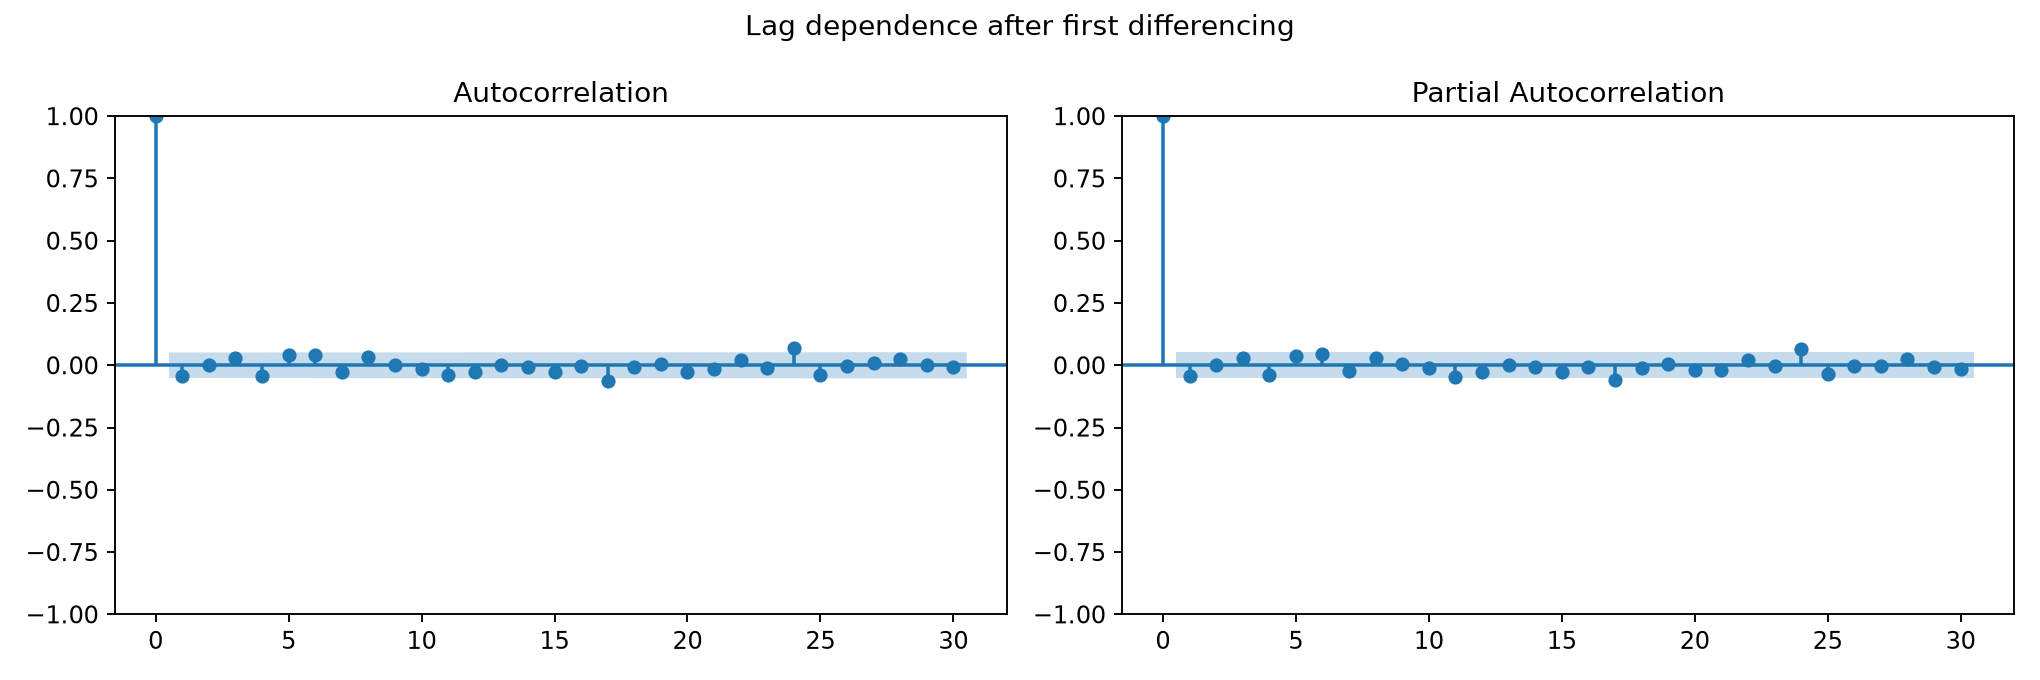

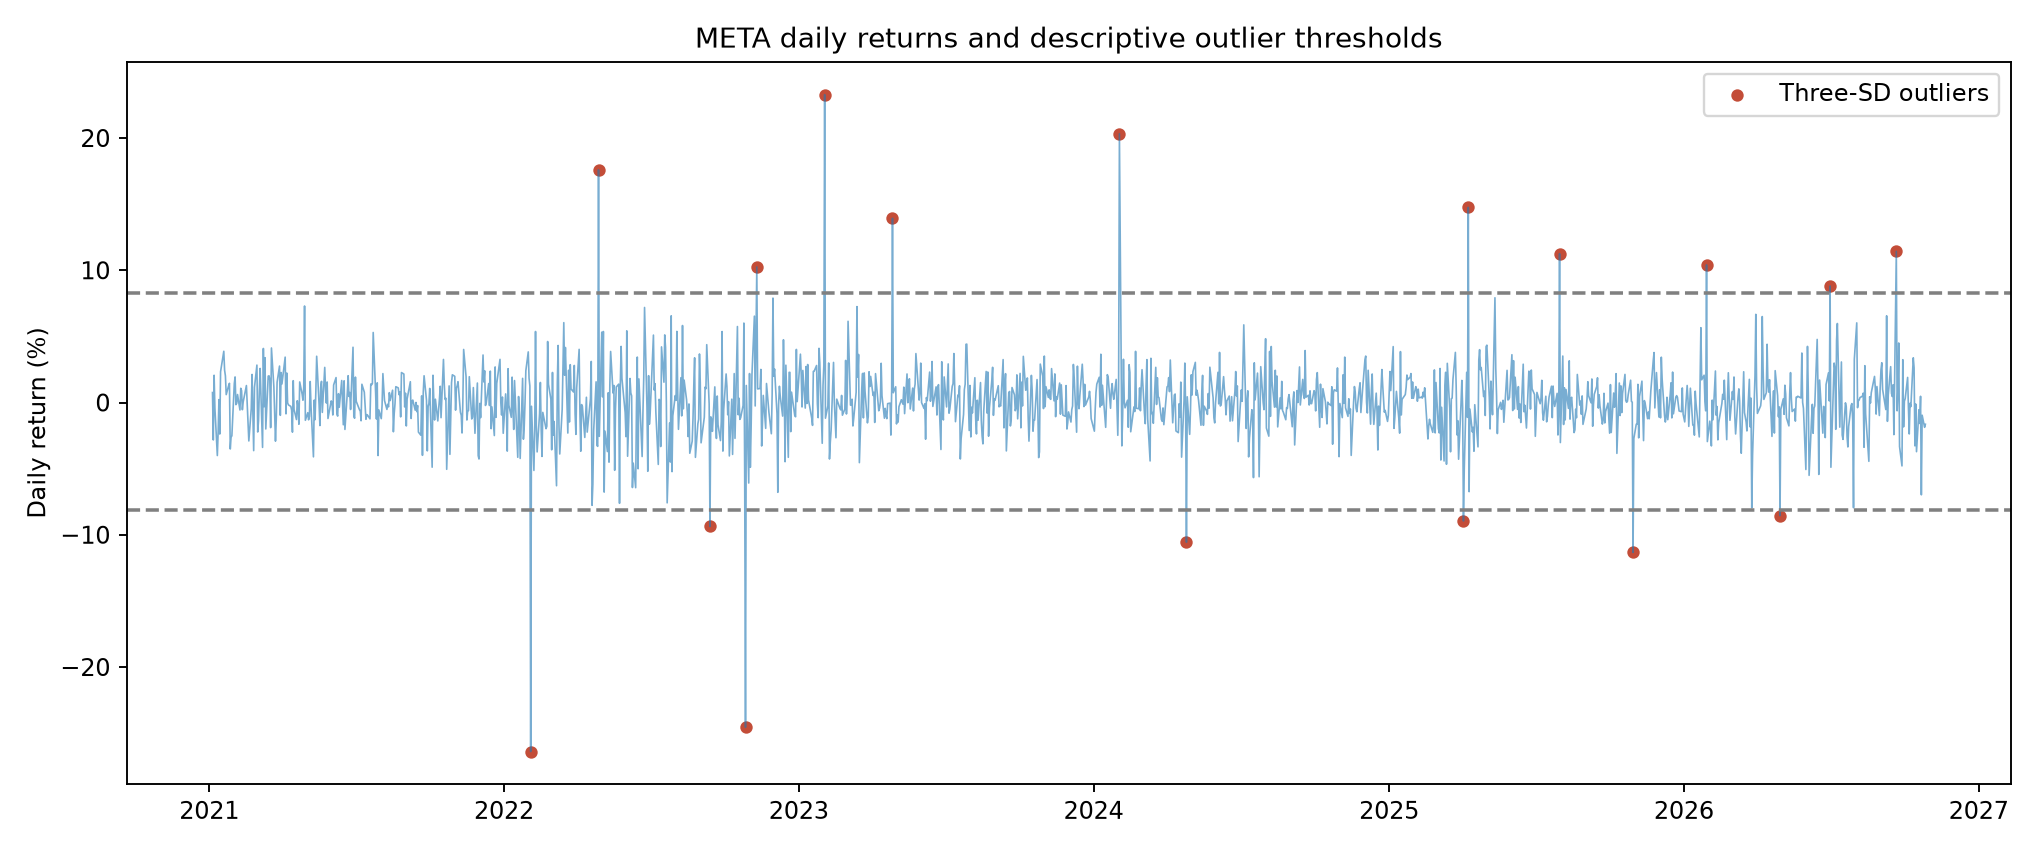

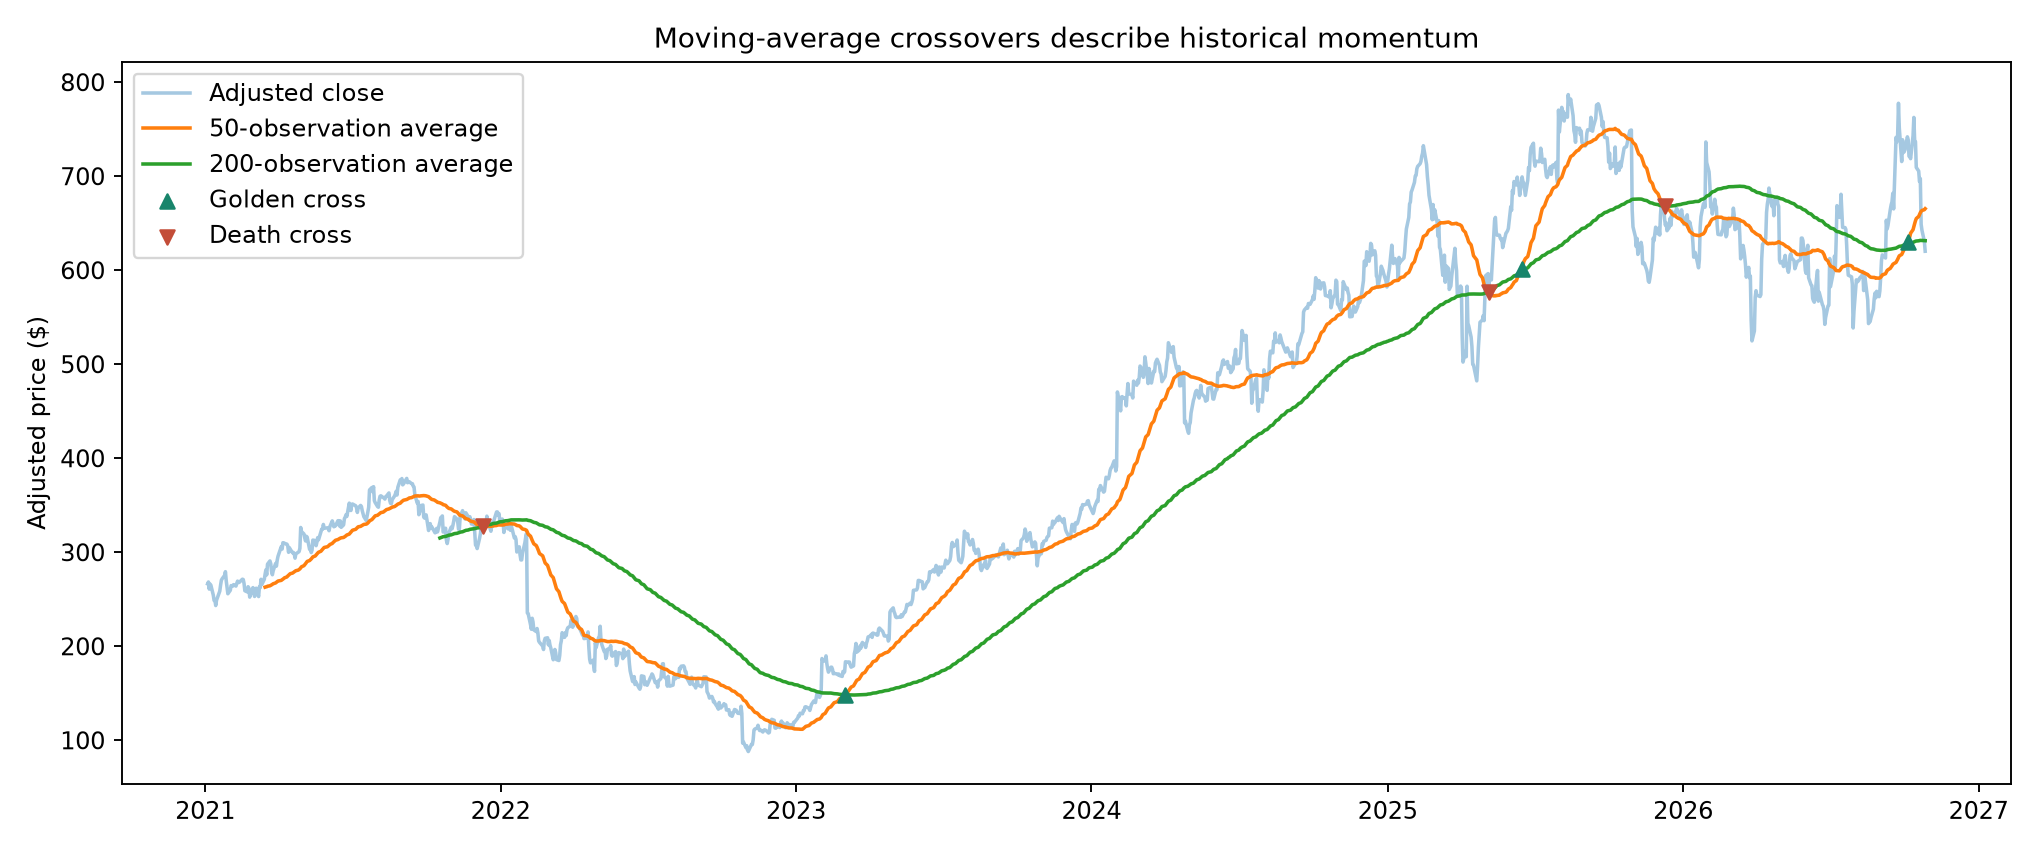

In [3]:
from IPython.display import Image, display
display(Image(filename='results/acf_pacf.png'))
display(Image(filename='results/return_outliers.png'))
display(Image(filename='results/moving_average_crossovers.png'))

## Reproducibility

Regenerated for the portfolio on October 28, 2026. See ../VALIDATION.md for comparisons with original course results. Associations and descriptive trend signals do not establish causation or guarantee future outcomes.